<a href="https://colab.research.google.com/github/jyujolie/mnist-cnn/blob/main/CNN%E6%89%8B%E5%86%99%E6%95%B0%E5%AD%97%E8%AF%86%E5%88%AB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 基于 CNN 的手写数字识别

本项目使用 MNIST 数据集识别 0～9 的手写数字。MNIST 包含 60,000 张训练图片和 10,000 张测试图片，每张是 28×28 的灰度图。测试集只用于训练完成后的评估。

模型依次使用两组卷积层和最大池化层提取图像特征，再通过展平层与全连接层输出 10 个数字类别的概率。训练设置为 5 轮、批量大小 128，并从训练数据中划出 10% 作为验证集。


In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("训练图片：", x_train.shape)
print("测试图片：", x_test.shape)
print("第一张图片的正确答案：", y_train[0])

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
训练图片： (60000, 28, 28)
测试图片： (10000, 28, 28)
第一张图片的正确答案： 5


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 30830 (\N{CJK UNIFIED IDEOGRAPH-786E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 23383 (\N{CJK UNIFIED IDEOGRAPH-5B57}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figu

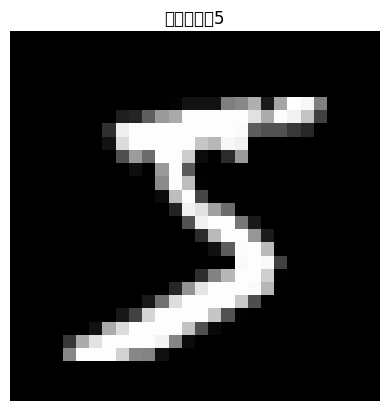

In [2]:
plt.imshow(x_train[0], cmap="gray")
plt.title(f"正确数字：{y_train[0]}")
plt.axis("off")
plt.show()

In [3]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train[..., tf.newaxis]
x_test = x_test[..., tf.newaxis]

print(x_train.shape)

(60000, 28, 28, 1)


In [4]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 106ms/step - accuracy: 0.9246 - loss: 0.2583 - val_accuracy: 0.9812 - val_loss: 0.0667
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 104ms/step - accuracy: 0.9790 - loss: 0.0690 - val_accuracy: 0.9850 - val_loss: 0.0562
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 80s 100ms/step - accuracy: 0.9850 - loss: 0.0489 - val_accuracy: 0.9882 - val_loss: 0.0413
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9888 - loss: 0.0378 - val_accuracy: 0.9895 - val_loss: 0.0392
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9908 - loss: 0.0309 - val_accuracy: 0.9875 - val_loss: 0.0433


## 测试集结果

已有运行记录显示测试集准确率为 **98.79%**。以下单元格会按当前训练得到的模型重新计算准确率，因此重新运行时数值可能略有变化。


In [6]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"测试集准确率：{test_accuracy:.2%}")

测试集准确率：98.79%


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 65307 (\N{FULLWIDTH SEMICOLON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 31572 (\N{CJK UNIFIED IDEOGRAPH-7B54}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 26696 (\N{CJK UNIFIED IDEOGRAPH-6848}) missing from font(s) DejaVu Sans.
  fig.canvas.print_

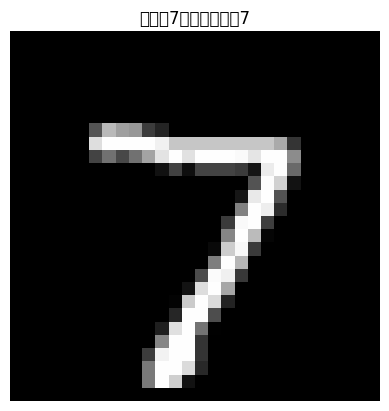

In [7]:
predictions = model.predict(x_test[:1], verbose=0)
predicted_digit = predictions[0].argmax()

plt.imshow(x_test[0, :, :, 0], cmap="gray")
plt.title(f"预测：{predicted_digit}；正确答案：{y_test[0]}")
plt.axis("off")
plt.show()

## 预测正确与错误的例子

上排展示 4 张预测正确的图片，下排展示 4 张预测错误的图片。标题中的 `Pred` 是模型预测，`True` 是正确答案。观察错误样本可以帮助分析模型在哪些写法上容易混淆。


In [ ]:
import numpy as np

# 对整个测试集预测，分别找出前 4 个正确和错误的例子。
all_probabilities = model.predict(x_test, verbose=0)
all_predictions = np.argmax(all_probabilities, axis=1)
correct_indices = np.flatnonzero(all_predictions == y_test)[:4]
wrong_indices = np.flatnonzero(all_predictions != y_test)[:4]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, indices in enumerate([correct_indices, wrong_indices]):
    for column, ax in enumerate(axes[row]):
        if column >= len(indices):
            ax.axis('off')
            continue
        i = indices[column]
        ax.imshow(x_test[i, :, :, 0], cmap='gray')
        ax.set_title(f'Pred: {all_predictions[i]} | True: {y_test[i]}')
        ax.axis('off')

fig.suptitle('Top: correct predictions | Bottom: incorrect predictions')
plt.tight_layout()
plt.show()
print(f'正确示例 {len(correct_indices)} 张；错误示例 {len(wrong_indices)} 张')


In [11]:
model.save("mnist_cnn.keras")